# Objectif 

Calcul des grandeurs signantes pour la portion event ais 5, et comparaison de l'event à une librairie de référence construite à partir de la portion 5.

Date de création : 29/10/2026

Les fonctions développées dans ce notebook sont maintenant dans les modules `acouplane_event.py` (librairie, harmonisation, MFP library/event), `acouplane_features.py` (distances), `acouplane_combination.py` (combinaison de capteurs) et `acouplane_plot_event.py` (figures). Le script `acouplane_analyse_portion_event_ais.py` enchaîne les mêmes étapes de façon autonome.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_combination import (
    combination_intersection_positions,
    enumerate_rcv_combinations,
    format_rcv_combination,
    rcv_combination_records,
)
from real_data_analysis.acouplane.src.acouplane_conventions import library_event_error_mode
from real_data_analysis.acouplane.src.acouplane_event import (
    apply_mfp_strategy_to_portions,
    build_portion_library,
    derive_portion_cpsd_welch,
    derive_portion_features,
    get_crossing_distance_m,
)
from real_data_analysis.acouplane.src.acouplane_localization import (
    add_validity_column,
    select_and_order_distance_types,
    summarize_localization_errors,
)
from real_data_analysis.acouplane.src.acouplane_plot_analysis import plot_metric_vs_n_rcv
from real_data_analysis.acouplane.src.acouplane_plot_event import (
    plot_event_features,
    plot_library_and_event_map,
)
from real_data_analysis.acouplane.src.acouplane_plot_mfp import plot_combined_intersection_ambiguity
from real_data_analysis.acouplane.src.acouplane_portion_io import list_stored_intersections, open_portion

# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. Les fichiers sont ouverts de façon paresseuse (rien n'est chargé en mémoire avant l'accès aux valeurs).

In [3]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = open_portion(fpath)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

In [4]:
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event = open_portion(fpath)
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 1)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 8B ...
│   Attributes:
│       box_lon_min:       5.919009015
│       box_lon_max:       5.965350184499999
│       box_lat_min:       42.973826338
│       box_lat_max:       43.07525886599999
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   └── Group: /position/event_0
│           Dimensions:         (datetime: 127)
│           Coordinates:
│             * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T20:28:50 ... 202...
│           Data variables:
│               lon             (datetime) float64 1kB ...
│               lat             (datetime) float64 1kB ...
│               start_datetime  datetime64[ns] 8B ...
│               stop_datetime   datetime64[ns] 8B ...
│           Attributes:
│               description:              Positions AIS interpolées
│               interpolation_time_step:  10s
│               campagne:                 ACOUPLANE
│               geodesic_frame:           WGS84
│               event_id:                 0
│               MMSI:                     61
└── Group: /pressure
    └── Group: /pressure/event_0
            Dimensions:         (time_obs1: 2520001, time_obs2: 2520001,
                                 time_obs4: 2520001, time_obs5: 2520001,
                                 time_obs6: 2520001, time_obs7: 2520001, obs_id: 6)
            Coordinates:
              * time_obs1       (time_obs1) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs2       (time_obs2) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs4       (time_obs4) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs5       (time_obs5) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs6       (time_obs6) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * time_obs7       (time_obs7) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
              * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
            Data variables:
                pressure_obs1   (time_obs1) float64 20MB ...
                pressure_obs2   (time_obs2) float64 20MB ...
                pressure_obs4   (time_obs4) float64 20MB ...
                pressure_obs5   (time_obs5) float64 20MB ...
                pressure_obs6   (time_obs6) float64 20MB ...
                pressure_obs7   (time_obs7) float64 20MB ...
                start_datetime  (obs_id) datetime64[ns] 48B ...
            Attributes:
                description:  Données de pression (voie hydro 3)
                campagne:     ACOUPLANE
                fs:           2000
                fullscale:    4.52
                event_id:     0

# Rappel de la situation : grille de la librairie et position des trajectoires events 

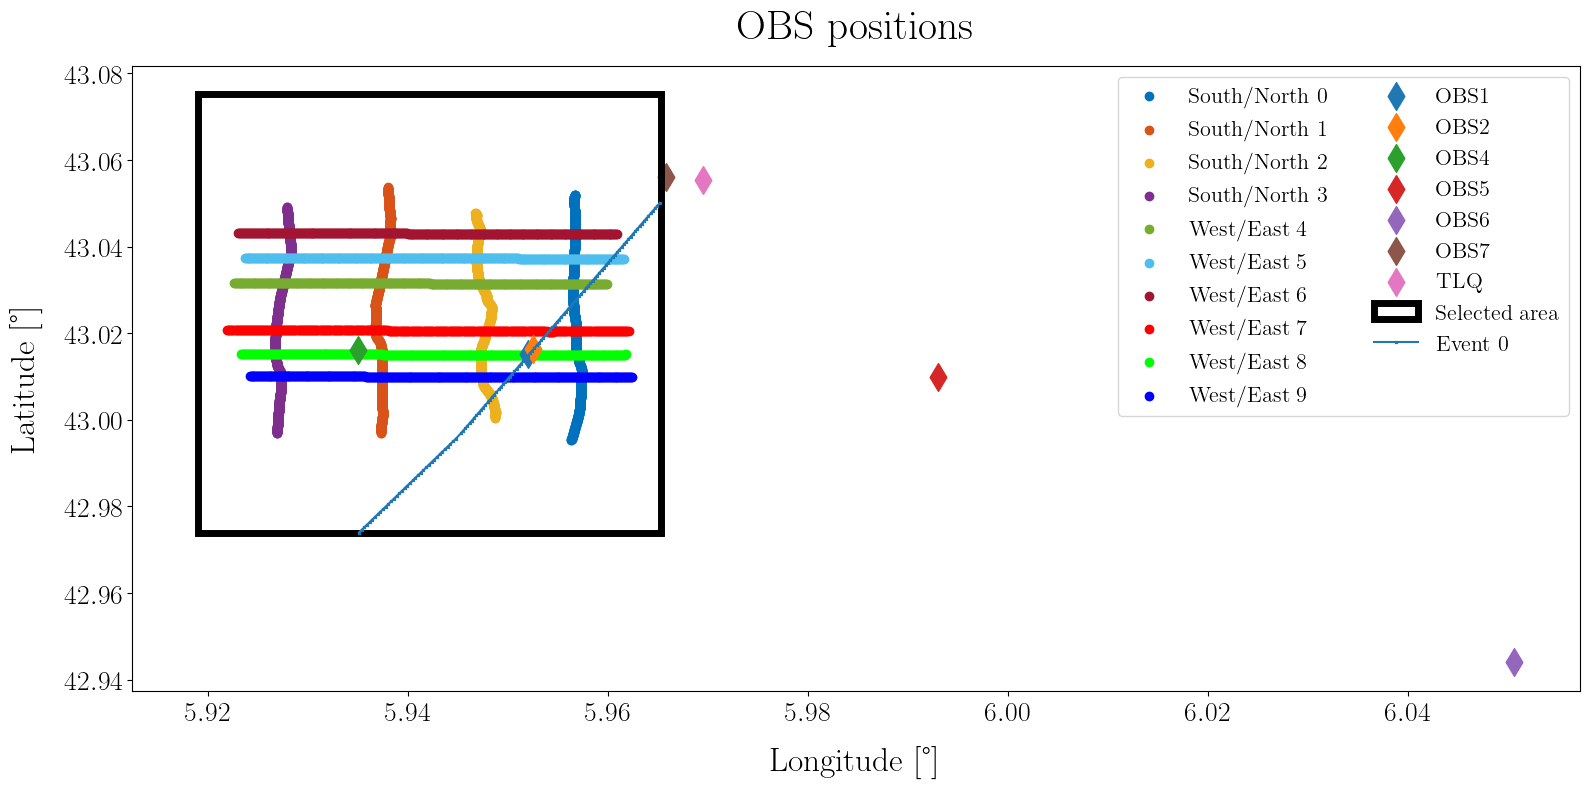

In [5]:
fig, ax = plot_library_and_event_map(portion=portion, portion_event=portion_event)

# Approche 1 : calcul des RTF similaire au cas actif

On suppose le bruit négligeable et on estime les densités spectrales croisées à l'aide de la méthode de Welch. 

Le rapport des fonctions de transfert est ensuite simplement estimé par : 
$$
\Pi(f) = \frac{S_{21}(f)}{S_{11}(f)}
$$

Le capteur de référence `reference_rcv` est le même pour la librairie et pour l'event : il est passé explicitement aux deux étapes de construction des features, puis vérifié avant la comparaison.

In [6]:
# Frequency band, reference receiver and receivers used (same for the library and the event)
fmin = 10
fmax = 150
reference_rcv = "obs1"
obs_ids = ["obs1", "obs2", "obs4", "obs5", "obs6", "obs7"]

# CPSD of the event (Welch)
nfft = 2**13
nperseg = 2**13
noverlap = 2**12

derive_portion_cpsd_welch(
    portion_tree=portion_event,
    analysis_segment_duration_s=6,
    analysis_segment_alpha_overlap=0.75,
    nfft=nfft,
    noverlap=noverlap,
    nperseg=nperseg,
    obs_ids=None,
    fmin=fmin,
    fmax=fmax,
)

In [7]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 1)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 8B ...
│   Attributes:
│       box_lon_min:       5.919009015
│       box_lon_max:       5.965350184499999
│       box_lat_min:       42.973826338
│       box_lat_max:       43.07525886599999
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   └── Group: /position/event_0
│           Dimensions:         (datetime: 127)
│           Coordinates:
│             * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T20:28:50 ... 202...
│           Data variables:
│               lon             (datetime) float64 1kB 5.935 5.935 5.936 ... 5.965 5.965
│               lat             (datetime) float64 1kB 42.97 42.97 42.98 ... 43.05 43.05
│               start_datetime  datetime64[ns] 8B ...
│               stop_datetime   datetime64[ns] 8B ...
│           Attributes:
│               description:              Positions AIS interpolées
│               interpolation_time_step:  10s
│               campagne:                 ACOUPLANE
│               geodesic_frame:           WGS84
│               event_id:                 0
│               MMSI:                     61
├── Group: /pressure
│   └── Group: /pressure/event_0
│           Dimensions:         (time_obs1: 2520001, time_obs2: 2520001,
│                                time_obs4: 2520001, time_obs5: 2520001,
│                                time_obs6: 2520001, time_obs7: 2520001, obs_id: 6)
│           Coordinates:
│             * time_obs1       (time_obs1) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
│             * time_obs2       (time_obs2) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
│             * time_obs4       (time_obs4) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
│             * time_obs5       (time_obs5) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
│             * time_obs6       (time_obs6) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
│             * time_obs7       (time_obs7) datetime64[ns] 20MB 2026-02-24T20:28:50 ... 2...
│             * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
│           Data variables:
│               pressure_obs1   (time_obs1) float64 20MB ...
│               pressure_obs2   (time_obs2) float64 20MB ...
│               pressure_obs4   (time_obs4) float64 20MB ...
│               pressure_obs5   (time_obs5) float64 20MB ...
│               pressure_obs6   (time_obs6) float64 20MB ...
│               pressure_obs7   (time_obs7) float64 20MB ...
│               start_datetime  (obs_id) datetime64[ns] 48B ...
│           Attributes:
│               description:  Données de pression (voie hydro 3)
│               campagne:     ACOUPLANE
│               fs:           2000
│               fullscale:    4.52
│               event_id:     0
└── Group: /feature
    └── Group: /feature/event_0
            Dimensions:         (event_datetime: 837, rcv_i: 6, rcv_j: 6, freq: 574)
            Coordinates:
              * event_datetime  (event_datetime) datetime64[ns] 7kB 2026-02-24T20:28:53 ....
              * rcv_i           (rcv_i) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
              * rcv_j           (rcv_j) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
              * freq            (freq) float64 5kB 10.01 10.25 10.5 ... 149.4 149.7 149.9
            Data variables:
                Sxy             (event_datetime, rcv_i, rcv_j, freq) complex128 277MB (4....
                event_lon       (event_datetime) float64 7kB 5.935 5.935 ... 5.965 5.965
                event_lat       (event_datetime) float64 7kB 42.97 42.97 ... 43.05 43.05
            Attributes:
                description:       Event localisation features
                section_label:     event_0
                acquisition_mode:  passive

In [8]:
# RTF and DCF features of the event
derive_portion_features(portion_event, rcv_ref=reference_rcv, fmin=fmin, fmax=fmax, verbose=True)

    Features of 'event_0' (reference receiver 'obs1')


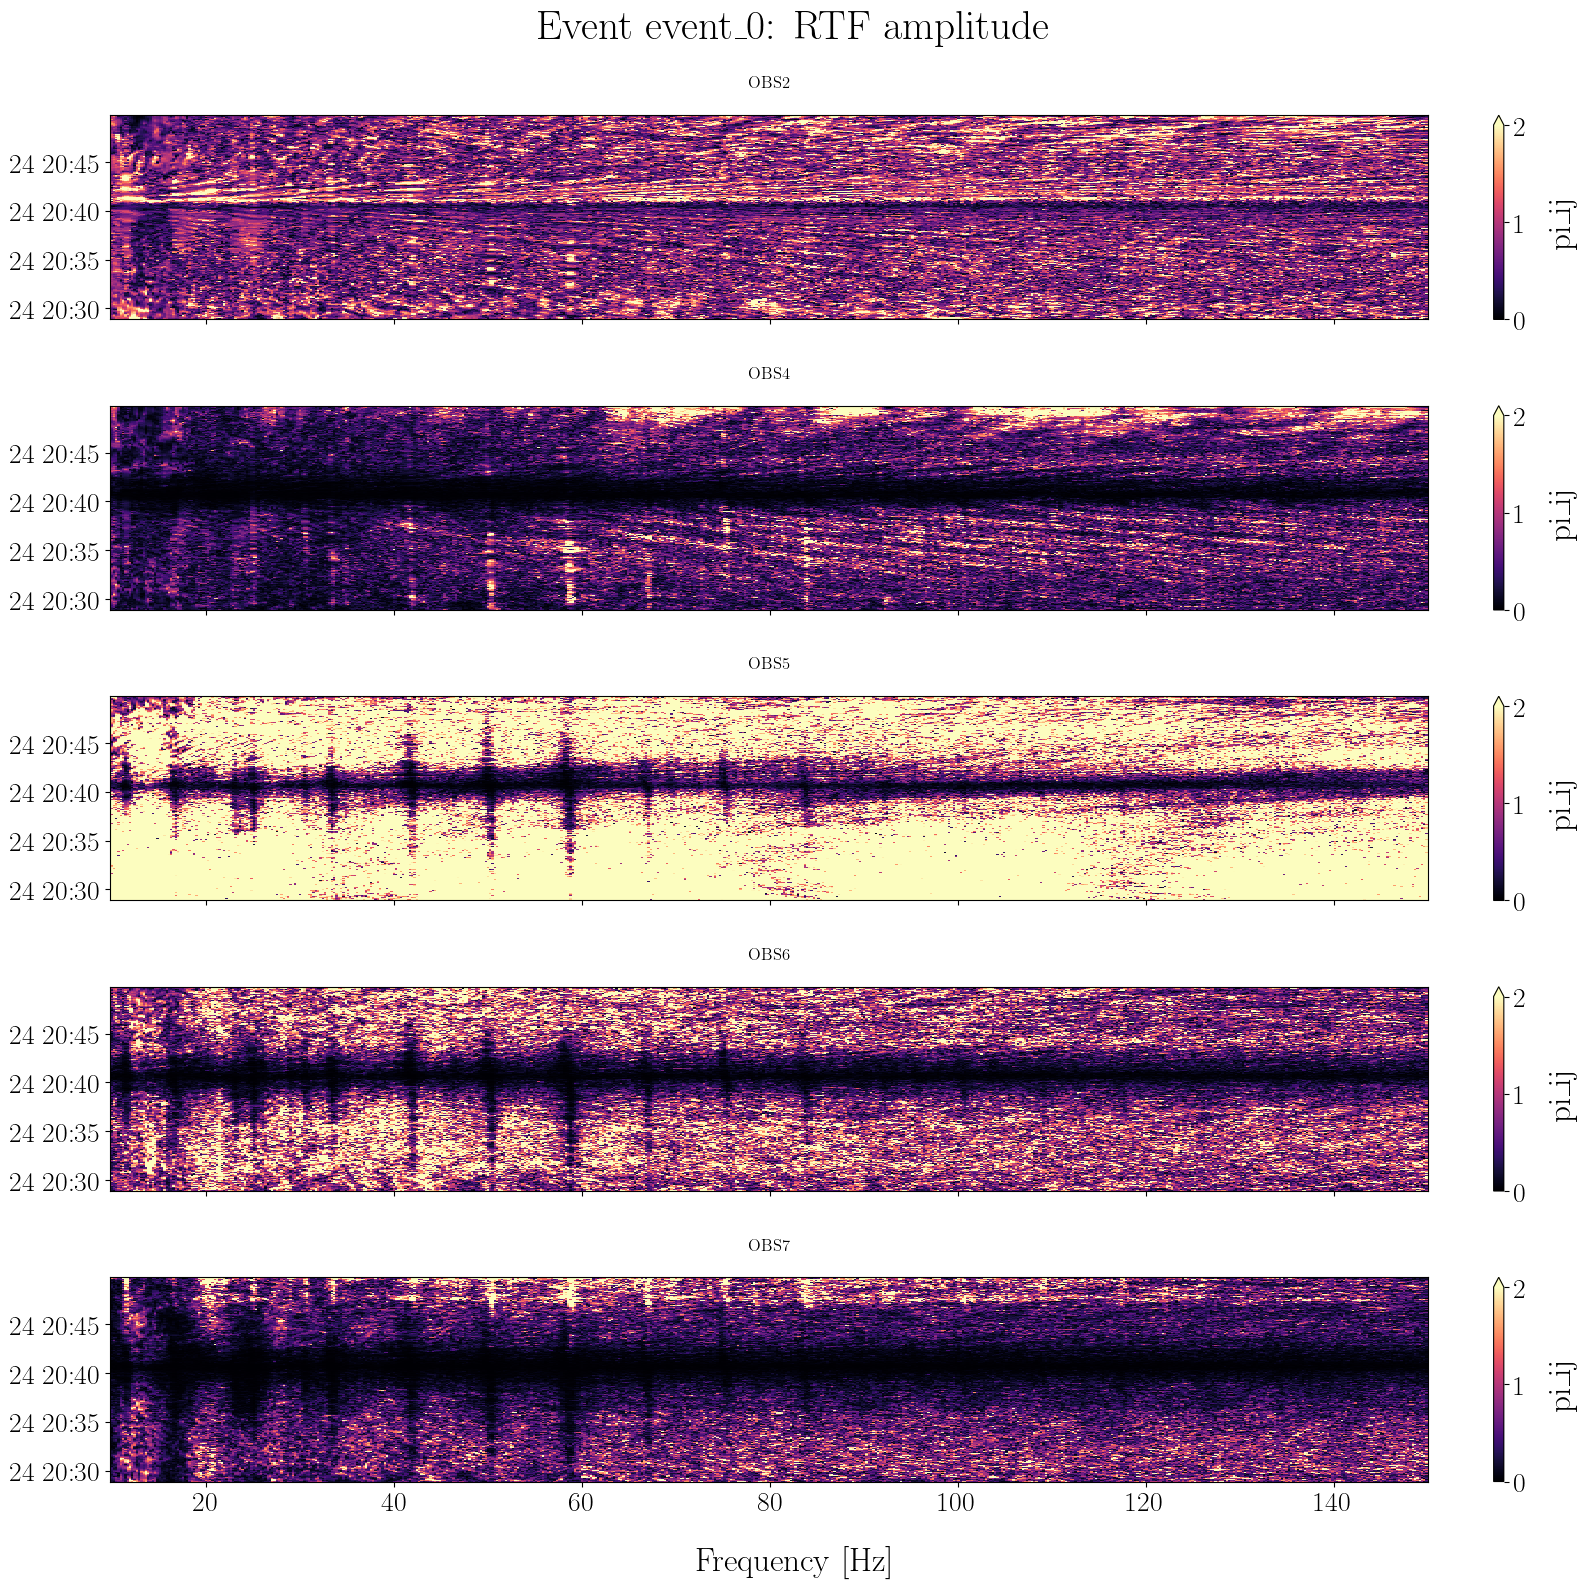

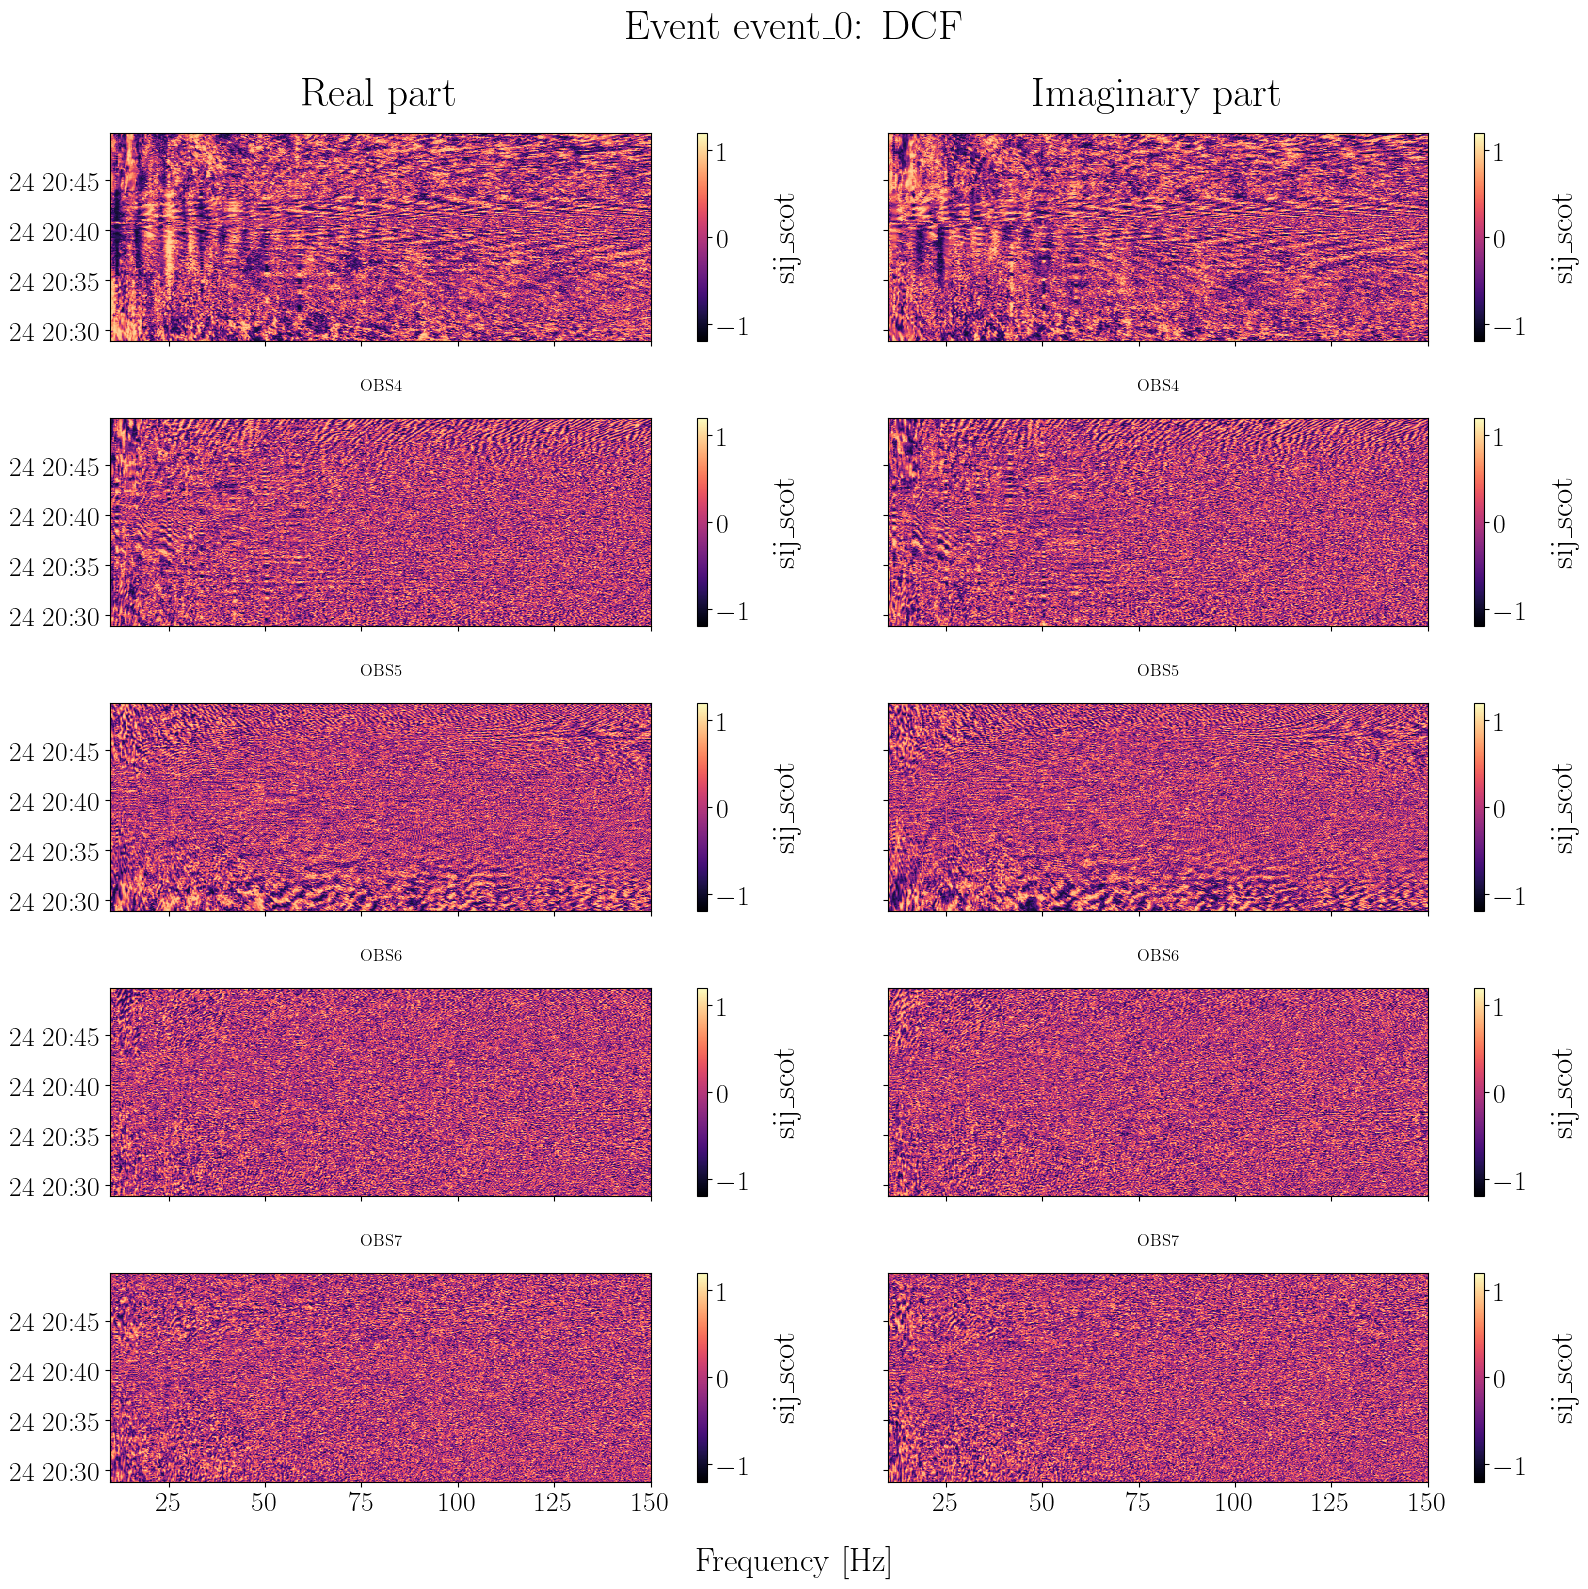

In [9]:
# Features of the event (RTF amplitude and DCF)
for name, node in portion_event.feature.children.items():
    fig_rtf, fig_dcf = plot_event_features(node.to_dataset())
    fig_rtf.suptitle(f"Event {name}: RTF amplitude")
    fig_dcf.suptitle(f"Event {name}: DCF")
    plt.show()

# Librairie de référence : `portion_library`

La librairie est construite à partir de sections de la portion 5 (émissions actives). Seules les informations utiles à la comparaison sont conservées (features RTF / DCF, position de la source à chaque échantillon, position des capteurs). La structure est la même que celle de `portion_event` :

- `/position/<section>` : `datetime`, `lon`, `lat` ;
- `/feature/<section>` : `library_datetime`, `library_lon`, `library_lat`, `pi_ij`, `gamma_ij`, `sij_scot`.

Pour le cas passif/passif, il suffira de construire la librairie avec `acquisition_mode="passive"` à partir d'events dont la trajectoire est connue : le reste du traitement est inchangé.

In [10]:
# Sections of the portion kept in the library
sections = ["sn2"]
# sections = ["sn0", "sn2", "oe7", "oe8", "oe9"]

portion_library = build_portion_library(
    portion,
    sections=sections,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    acquisition_mode="active",
    verbose=True,
)
portion_library

    Library section 'sn2' (active)


<xarray.DataTree>
Group: /
│   Attributes:
│       description:         Library of reference features
│       acquisition_mode:    active
│       reference_receiver:  obs1
├── Group: /position
│   └── Group: /position/sn2
│           Dimensions:   (datetime: 685)
│           Coordinates:
│             * datetime  (datetime) datetime64[ns] 5kB 2026-02-25T07:28:00.600098 ... 20...
│           Data variables:
│               lon       (datetime) float64 5kB 5.947 5.947 5.947 ... 5.949 5.949 5.949
│               lat       (datetime) float64 5kB 43.05 43.05 43.05 43.05 ... 43.0 43.0 43.0
│           Attributes:
│               description:            Localisation features
│               campagne:               ACOUPLANE
│               geodesic_frame:         WGS84
│               portion_id:             5
│               section_orientation:    South/North
│               section_id:             2
│               section_label:          sn2
│               obs_position:           OBS position corrected using LMS inversion.
│               obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
│               reference_receiver:     obs1
│               acquisition_mode:       active
└── Group: /feature
    └── Group: /feature/sn2
            Dimensions:           (rcv_id_feature: 5, library_datetime: 685, freq: 574,
                                   rcv_id: 7)
            Coordinates:
              * rcv_id_feature    (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs6' 'obs7'
              * library_datetime  (library_datetime) datetime64[ns] 5kB 2026-02-25T07:28:...
              * freq              (freq) float64 5kB 10.01 10.25 10.5 ... 149.4 149.7 149.9
              * rcv_id            (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
            Data variables:
                pi_ij             (rcv_id_feature, library_datetime, freq) complex64 16MB ...
                gamma_ij          (rcv_id_feature, library_datetime, freq) float32 8MB 1....
                sij_scot          (rcv_id_feature, library_datetime, freq) complex64 16MB ...
                library_lon       (library_datetime) float64 5kB 5.947 5.947 ... 5.949 5.949
                library_lat       (library_datetime) float64 5kB 43.05 43.05 ... 43.0 43.0
                rcv_lon           (rcv_id) float64 56B ...
                rcv_lat           (rcv_id) float64 56B ...
                rcv_immersion     (rcv_id) int16 14B ...
            Attributes:
                description:            Localisation features
                campagne:               ACOUPLANE
                geodesic_frame:         WGS84
                portion_id:             5
                section_orientation:    South/North
                section_id:             2
                section_label:          sn2
                obs_position:           OBS position corrected using LMS inversion.
                obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
                reference_receiver:     obs1
                acquisition_mode:       active

# Surfaces d'ambiguïté entre la librairie et l'event

La distance dans l'espace réel est calculée par `get_distance_between_library_and_event` (distance géodésique entre les échantillons de la librairie et ceux de l'event). Les distances dans l'espace des features sont communes au cas actif et au cas passif.

In [11]:
portion_mfp = apply_mfp_strategy_to_portions(
    portion_library=portion_library,
    portion_event=portion_event,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    verbose=True,
    compare_centered_gamma=True,
    library_sections=None,
    event_sections=None,
    obs_ids=obs_ids,
)

    Library 'sn2' x event 'event_0' (1/1)


In [12]:
portion_mfp

<xarray.DataTree>
Group: /
│   Attributes:
│       description:         MFP between a library and events
│       reference_receiver:  obs1
└── Group: /mfp_intersection
    └── Group: /mfp_intersection/sn2
        └── Group: /mfp_intersection/sn2/event_0
                Dimensions:                 (rcv_id: 7, library_datetime: 685,
                                             event_datetime: 837, rcv_id_feature: 5)
                Coordinates:
                  * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
                  * library_datetime        (library_datetime) datetime64[ns] 5kB 2026-02-25T...
                  * event_datetime          (event_datetime) datetime64[ns] 7kB 2026-02-24T20...
                  * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
                Data variables: (12/14)
                    rcv_lon                 (rcv_id) float64 56B ...
                    rcv_lat                 (rcv_id) float64 56B ...
                    rcv_immersion           (rcv_id) int16 14B ...
                    library_lon             (library_datetime) float64 5kB 5.947 5.947 ... 5.949
                    library_lat             (library_datetime) float64 5kB 43.05 43.05 ... 43.0
                    event_lon               (event_datetime) float64 7kB 5.935 5.935 ... 5.965
                    ...                      ...
                    d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 23MB ...
                    d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 23MB ...
                    d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 23MB ...
                    d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 23MB ...
                    d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 23MB ...
                    d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 23MB ...
                Attributes:
                    description:               MFP result for a library section and an event
                    campagne:                  ACOUPLANE
                    section1:                  sn2
                    section2:                  event_0
                    library_acquisition_mode:  active
                    event_acquisition_mode:    passive
                    reference_receiver:        obs1
                    obs_position:              OBS position corrected using LMS inversion.
                    obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...

# Intersection théorique et intersection estimée

- **Théorique** : couple (échantillon de la librairie, échantillon de l'event) le plus proche dans l'espace réel, i.e. là où la trajectoire AIS croise la section.
- **Estimée** : couple minimisant la surface d'ambiguïté (combinée sur les capteurs choisis).

Si la trajectoire ne croise pas la section (`crossing_distance_m` grand), il n'y a pas d'intersection à retrouver.

Library sn2 / event event_0: closest samples 6 m apart


,kind,datetime1,lon1,lat1,datetime2,real_distance_m,error_side1_m,error_side2_m
0,theoretical,2026-02-25 07:59:15.600098,5.948359,43.005190,2026-02-24 20:37:15.500,6.096635,NaN,NaN
1,theta,2026-02-25 07:49:39.600098,5.947604,43.018150,2026-02-24 20:49:20.000,3620.868034,1441.079916,4961.124975
2,theta_gamma,2026-02-25 07:50:12.600098,5.947429,43.017380,2026-02-24 20:40:32.000,435.512950,1356.343928,1309.185757
3,L2_gamma,2026-02-25 07:49:51.600098,5.947545,43.017870,2026-02-24 20:42:17.000,853.050092,1410.221033,2067.135406
4,dcf,2026-02-25 07:59:24.600098,5.948390,43.005002,2026-02-24 20:43:05.000,2435.970552,21.037840,2411.657974
5,theta_gamma_centered,2026-02-25 07:59:54.600098,5.948481,43.004375,2026-02-24 20:37:30.500,161.211318,91.085442,68.904514
6,L2_gamma_centered,2026-02-25 07:49:51.600098,5.947545,43.017870,2026-02-24 20:41:12.500,505.246236,1410.221033,1584.803811


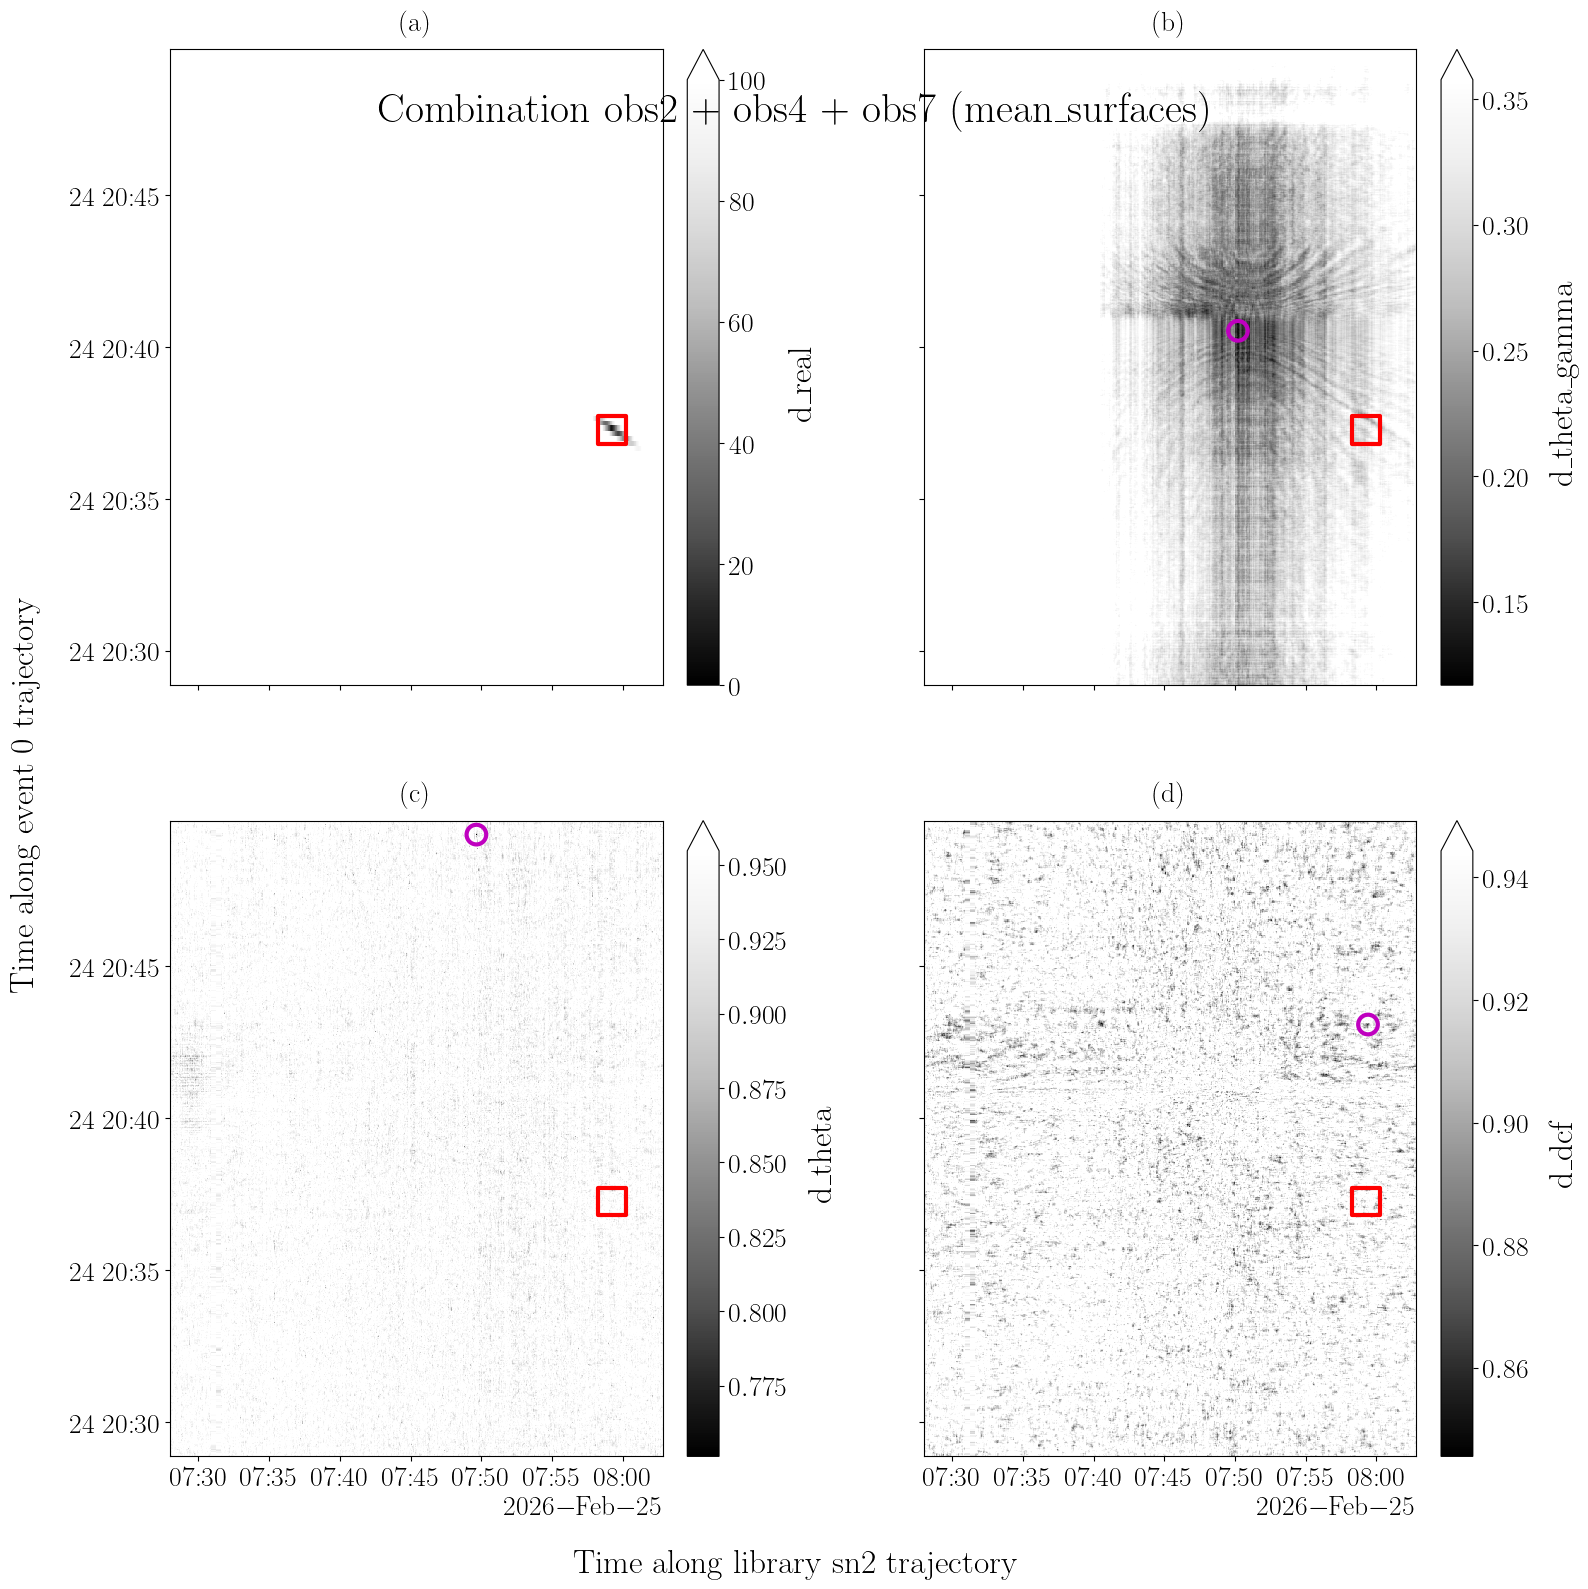

In [13]:
# Combination of receivers used for the figures and the table below
rcv_combination = ["obs2", "obs4", "obs7"]
combination_method = "mean_surfaces"
max_crossing_distance_m = 200

for name_lib, name_event in list_stored_intersections(portion_mfp):
    ds_mfp = portion_mfp[f"/mfp_intersection/{name_lib}/{name_event}"].to_dataset()

    # Does the trajectory cross the library section ?
    crossing_distance_m = get_crossing_distance_m(ds_mfp)
    print(f"Library {name_lib} / event {name_event}: closest samples {crossing_distance_m:.0f} m apart")
    if crossing_distance_m > max_crossing_distance_m:
        print("    no intersection: skipped")
        continue

    # Theoretical and estimated intersections
    positions = pd.DataFrame(
        combination_intersection_positions(ds_mfp, rcv_combination, method=combination_method)
    )
    display(positions[["kind", "datetime1", "lon1", "lat1", "datetime2", "real_distance_m", "error_side1_m", "error_side2_m"]])

    # Ambiguity surfaces with the theoretical (red square) and estimated (magenta circle) intersections
    event_id = portion_event.position[name_event].to_dataset().attrs.get("event_id", name_event)
    fig = plot_combined_intersection_ambiguity(
        ds_mfp,
        rcv_combination,
        section1_name=f"library {name_lib}",
        section2_name=f"event {event_id}",
        method=combination_method,
        cmap="Grays_r",
        max_quantile=0.5,
        d_real_vmax=100,
    )
    plt.show()

# Évaluation des combinaisons de capteurs

Même méthodologie que pour le cas actif : toutes les combinaisons de capteurs sont évaluées (moyenne des surfaces d'ambiguïté des paires `(obs_i, référence)`), l'erreur de position est mesurée entre l'intersection estimée et l'intersection théorique. `error_mode` vaut `"library"` (position le long de la section de la librairie), `"event"` (position le long de la trajectoire) ou `"both"`.

In [14]:
error_mode = "library"
success_threshold_m = 100
contrast_percentile = 50

# Comparisons whose trajectory crosses a library section
datasets_mfp = {}
for name_lib, name_event in list_stored_intersections(portion_mfp):
    ds_mfp = portion_mfp[f"/mfp_intersection/{name_lib}/{name_event}"].to_dataset()
    if get_crossing_distance_m(ds_mfp) <= max_crossing_distance_m:
        datasets_mfp[(name_lib, name_event)] = ds_mfp

# Receivers available for all the comparisons, and all their combinations
available_rcv_ids = [
    str(rcv_id) for rcv_id in next(iter(datasets_mfp.values()))["rcv_id_feature"].values
]
combinations = enumerate_rcv_combinations(
    available_rcv_ids, sizes=None, combinations=None, max_combinations=200
)

# Position error and contrast of every combination
records = []
for (name_lib, name_event), ds_mfp in datasets_mfp.items():
    records += rcv_combination_records(
        ds_mfp,
        combinations,
        reference_rcv=reference_rcv,
        error_mode=library_event_error_mode(error_mode),
        percentile=contrast_percentile,
        method=combination_method,
        intersection=f"{name_lib} x {name_event}",
    )

df_records, distance_types = select_and_order_distance_types(pd.DataFrame(records), None)
df_records = add_validity_column(df_records, success_threshold_m)
df_records.head()

,combination,n_rcv,method,intersection,distance_type,rcv_id,rcv_pair,error_m,contrast,valid
0,obs2,1,mean_surfaces,sn2 x event_0,theta,obs2,"(obs2, obs1)",3486.891284,0.247759,False
1,obs4,1,mean_surfaces,sn2 x event_0,theta,obs4,"(obs4, obs1)",856.811479,0.331844,False
2,obs5,1,mean_surfaces,sn2 x event_0,theta,obs5,"(obs5, obs1)",4370.931779,0.262152,False
3,obs6,1,mean_surfaces,sn2 x event_0,theta,obs6,"(obs6, obs1)",2897.425532,0.270192,False
4,obs7,1,mean_surfaces,sn2 x event_0,theta,obs7,"(obs7, obs1)",1441.079916,0.574649,False


,distance_type,rcv_pair,n_intersections,n_valid,mean_error_m,median_error_m,std_error_m,rms_error_m,p90_error_m,success_rate
0,theta,"(obs2, obs1)",1,1,3486.891284,3486.891284,0.0,3486.891284,3486.891284,0.0
1,theta,"(obs4, obs1)",1,1,856.811479,856.811479,0.0,856.811479,856.811479,0.0
2,theta,"(obs5, obs1)",1,1,4370.931779,4370.931779,0.0,4370.931779,4370.931779,0.0
3,theta,"(obs6, obs1)",1,1,2897.425532,2897.425532,0.0,2897.425532,2897.425532,0.0
4,theta,"(obs7, obs1)",1,1,1441.079916,1441.079916,0.0,1441.079916,1441.079916,0.0
...,...,...,...,...,...,...,...,...,...,...
181,L2_gamma_centered,"(obs2 + obs4 + obs5 + obs7, obs1)",1,1,1410.221033,1410.221033,0.0,1410.221033,1410.221033,0.0
182,L2_gamma_centered,"(obs2 + obs4 + obs6 + obs7, obs1)",1,1,1410.221033,1410.221033,0.0,1410.221033,1410.221033,0.0
183,L2_gamma_centered,"(obs2 + obs5 + obs6 + obs7, obs1)",1,1,1410.221033,1410.221033,0.0,1410.221033,1410.221033,0.0
184,L2_gamma_centered,"(obs4 + obs5 + obs6 + obs7, obs1)",1,1,1410.221033,1410.221033,0.0,1410.221033,1410.221033,0.0


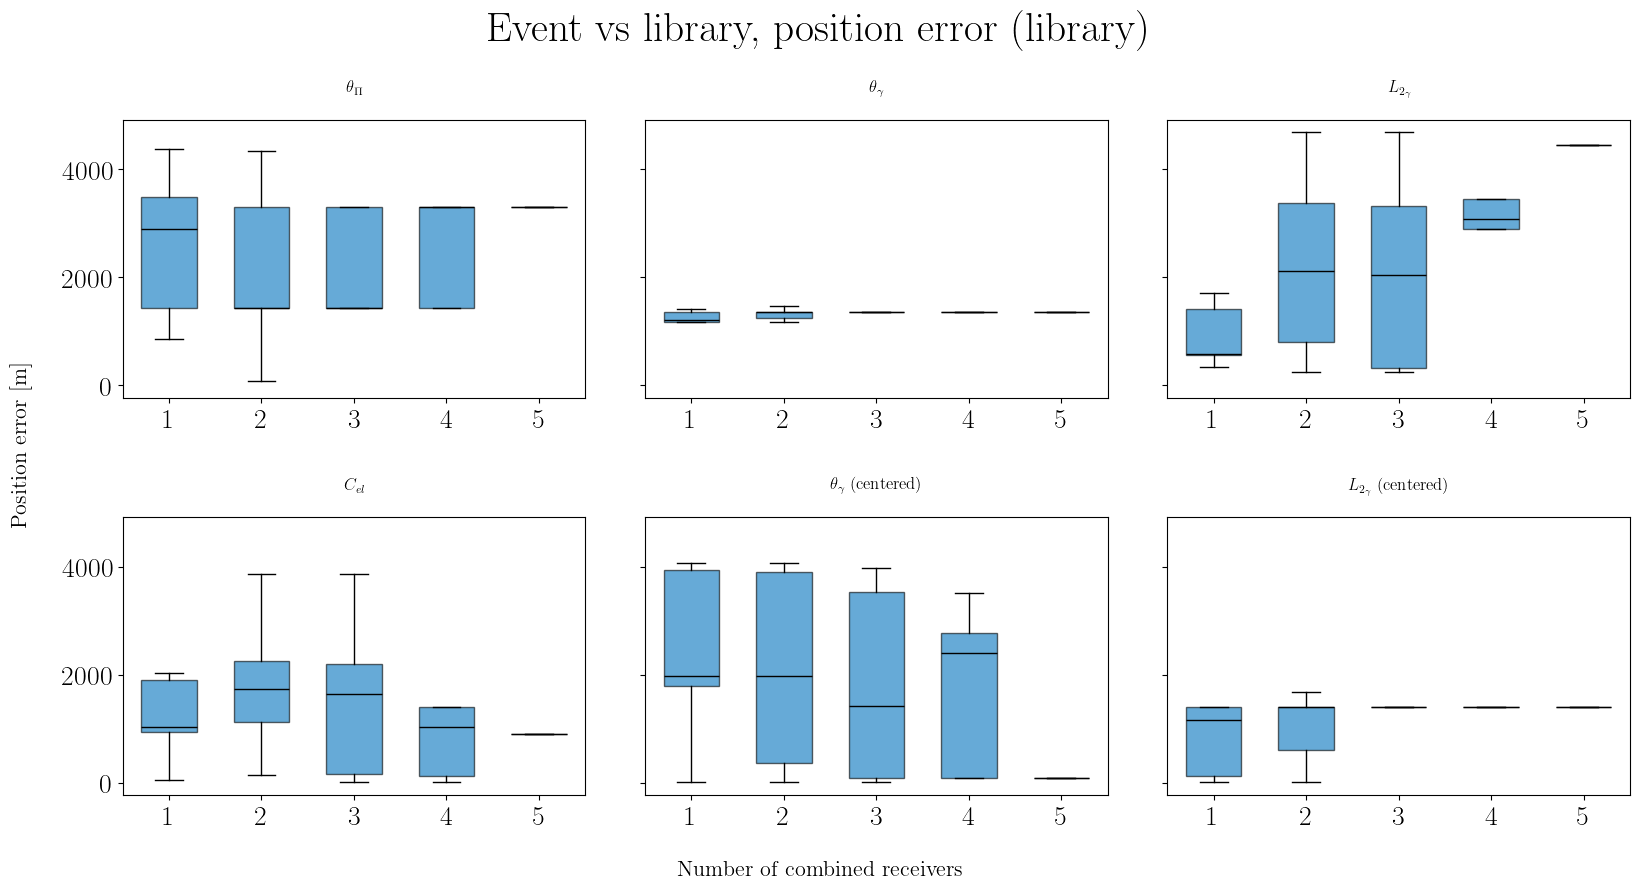

In [15]:
# Median error and success rate of every combination
summary = summarize_localization_errors(df_records, success_threshold_m)
display(summary)

# Position error versus number of combined receivers
fig = plot_metric_vs_n_rcv(
    df_records,
    distance_types,
    value_col="error_m",
    ylabel="Position error [m]",
    title=f"Event vs library, position error ({error_mode})",
)
plt.show()